# Week 3 — Visualization & Interpretation

This notebook uses the cleaned dataset from Week 1 and the findings from Week 2 to create five visualizations.

The Week 1 and Week 2 notebooks remain separate and unchanged. Here, `df` is created as a copy of `df_clean` so the visualizations and distance calculations do not modify the loaded cleaned dataset.

## 1. Imports and project paths

We use Pandas and NumPy for data preparation and calculations, and Matplotlib for the charts. Seaborn is imported because it is part of the project's visualization toolkit, although the five charts below use the Matplotlib style practiced in this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sb
from pathlib import Path

In [2]:
# Find the project folder whether the notebook is run from the root or notebooks folder
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / 'data' / 'processed' / 'cleaned_food_delivery.csv').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CLEANED_DATA_RELATIVE_PATH = 'data/processed/cleaned_food_delivery.csv'
CLEANED_DATA_PATH = PROJECT_ROOT / CLEANED_DATA_RELATIVE_PATH
VISUALIZATIONS_PATH = PROJECT_ROOT / 'visualizations'

# Create the visualizations folder if it does not already exist
VISUALIZATIONS_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Cleaned dataset found:", CLEANED_DATA_PATH.exists())

Project folder: C:\Users\DELL\food-delivery-data-analysis
Cleaned dataset found: True


In [3]:
# Load the cleaned dataset and create a separate working copy
df_clean = pd.read_csv(CLEANED_DATA_PATH)
df = df_clean.copy()

print("Dataset shape:", df.shape)

Dataset shape: (45584, 20)


## 2. Delivery Duration Distribution — Histogram

A histogram helps us understand how delivery durations are distributed. Each bar represents the number of deliveries within a duration interval.

We use 10 bins here to keep the distribution readable and consistent with the exploratory work from Week 2.

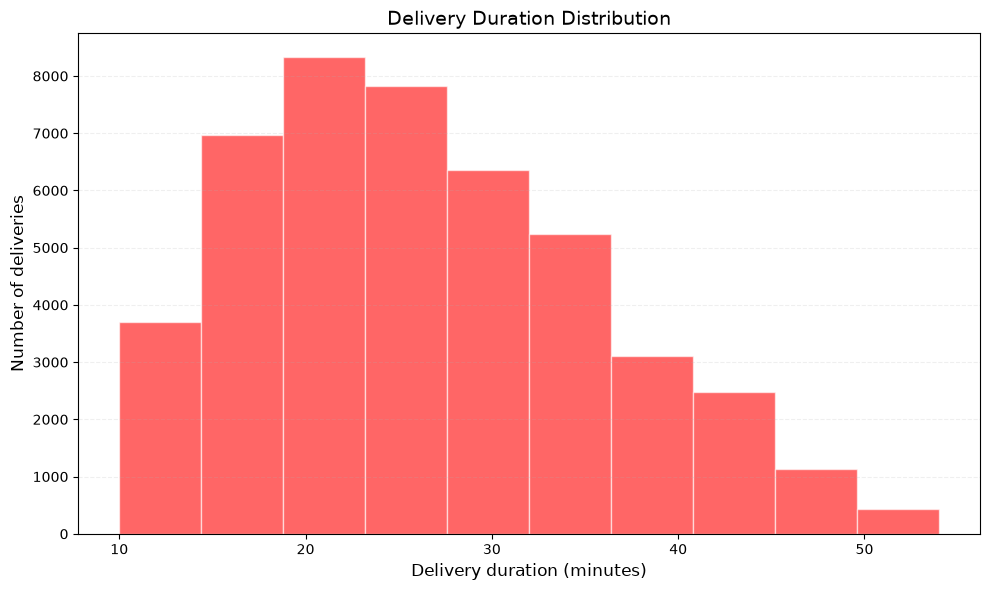

In [4]:
plt.figure(figsize=(10,6))

plt.hist(
    data=df,
    x='Time_taken (min)',
    bins=10,
    color='red',
    edgecolor='white',
    alpha=0.6
)

plt.title('Delivery Duration Distribution', fontsize=14)
plt.xlabel('Delivery duration (minutes)', fontsize=12)
plt.ylabel('Number of deliveries', fontsize=12)

plt.grid(axis='y', alpha=0.2, linestyle='--')
plt.tight_layout()

# Export the chart to the project visualizations folder
plt.savefig(VISUALIZATIONS_PATH / '01_delivery_duration_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()

### Interpretation

The histogram shows that delivery durations are mainly concentrated between approximately **19 and 30 minutes**. The distribution is **positively (right) skewed**: frequencies generally become lower as delivery duration increases, leaving a longer tail towards higher durations. The Week 2 IQR check identified **270 potential upper outliers**; these are unusual observations, but they should not automatically be treated as errors.

**Limitation:** The appearance of a histogram depends on the selected bin width. It shows the overall distribution but does not identify the individual deliveries behind each bar.

## 3. Traffic Comparison — Median Delivery Duration

We compare the median delivery duration across traffic categories. The median is useful here because it is less affected by unusually long delivery durations than the mean.

We also calculate the group size so that the number of observations behind each category is clear.

In [5]:
# Calculate the median duration and number of deliveries in each traffic category
traffic_summary = df.groupby('Road_traffic_density')['Time_taken (min)'].agg(
    median_duration='median',
    delivery_count='count'
).sort_values('median_duration', ascending=False)

traffic_summary

,median_duration,delivery_count
Road_traffic_density,,
Jam,31.0,14139
High,27.0,4423
Medium,27.0,10945
Low,20.0,15476


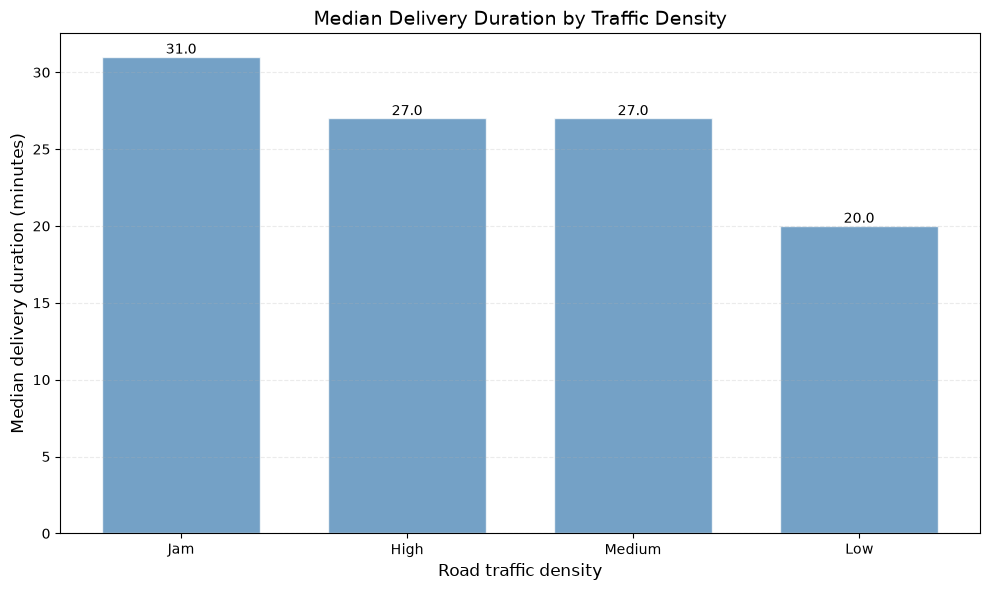

In [6]:
plt.figure(figsize=(10,6))

plt.bar(
    x=traffic_summary.index,
    height=traffic_summary['median_duration'],
    color='steelblue',
    alpha=0.75,
    width=0.7,
    edgecolor='white'
)

plt.title('Median Delivery Duration by Traffic Density', fontsize=14)
plt.xlabel('Road traffic density', fontsize=12)
plt.ylabel('Median delivery duration (minutes)', fontsize=12)

# Display the median above each bar
for i, value in enumerate(traffic_summary['median_duration']):
    plt.text(i, value, f'{value:.1f}', ha='center', va='bottom')

plt.grid(axis='y', alpha=0.25, linestyle='--')
plt.tight_layout()

plt.savefig(VISUALIZATIONS_PATH / '02_traffic_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

### Interpretation

Deliveries in **Jam** traffic have the highest median duration (**31 minutes**, 14,139 deliveries), while **Low** traffic has the lowest (**20 minutes**, 15,476 deliveries). High and Medium traffic both have a median of **27 minutes** (4,423 and 10,945 deliveries, respectively). These are differences between observed groups and do not prove that traffic alone causes longer delivery times.

**Limitation:** The chart compares medians, so it does not show the full spread of delivery durations within each traffic category. In addition, 601 records have a missing traffic category and are not included in this grouped comparison.

## 4. Weather Comparison — Average Delivery Duration

This chart compares the average (mean) delivery duration across weather categories. We calculate the mean and group size from the cleaned dataset, then display the mean values as bars.

In [7]:
# Calculate the mean duration and number of deliveries in each weather category
weather_summary = df.groupby('Weather_conditions')['Time_taken (min)'].agg(
    mean_duration='mean',
    delivery_count='count'
).sort_values('mean_duration', ascending=False)

weather_summary

,mean_duration,delivery_count
Weather_conditions,,
Cloudy,28.917164,7533
Fog,28.914674,7653
Windy,26.118836,7422
Sandstorms,25.875500,7494
Stormy,25.868803,7584
Sunny,21.856770,7282


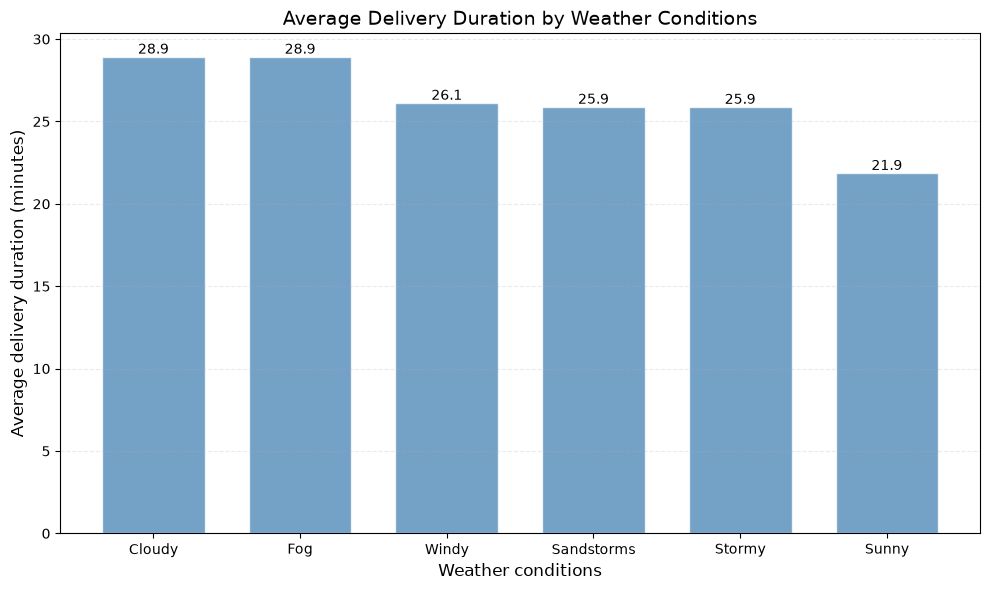

In [8]:
plt.figure(figsize=(10,6))

plt.bar(
    x=weather_summary.index,
    height=weather_summary['mean_duration'],
    color='steelblue',
    alpha=0.75,
    width=0.7,
    edgecolor='white'
)

plt.title('Average Delivery Duration by Weather Conditions', fontsize=14)
plt.xlabel('Weather conditions', fontsize=12)
plt.ylabel('Average delivery duration (minutes)', fontsize=12)

# Display the average above each bar
for i, value in enumerate(weather_summary['mean_duration']):
    plt.text(i, value, f'{value:.1f}', ha='center', va='bottom')

plt.grid(axis='y', alpha=0.25, linestyle='--')
plt.tight_layout()

plt.savefig(VISUALIZATIONS_PATH / '03_weather_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

### Interpretation

**Cloudy** and **Fog** conditions have the highest average delivery durations, at approximately **28.9 minutes** each. **Sunny** conditions have the lowest average, at approximately **21.9 minutes**, while Windy, Sandstorms and Stormy conditions are close to one another at approximately 25.9–26.1 minutes. These results show differences in observed averages, but they do not establish that weather conditions alone explain the differences.

**Limitation:** A mean does not show the spread of durations within each weather category and can be influenced by unusually long deliveries. Other factors, including traffic and distance, may also differ between groups.

## 5. Distance vs Delivery Duration — Scatter Plot

Week 2 compared two coordinate-handling scenarios. Here, we use **Scenario B**: exclude delivery coordinate pairs where both delivery latitude and longitude are between 0 and 1, exclude restaurant coordinates containing zero, and convert negative restaurant coordinates to their absolute values.

The absolute-value step is a sensitivity-analysis assumption, not a confirmed correction of the original geographic coordinates. We recalculate the distance here so this notebook can run independently of Week 2.

In [9]:
# Create an independent copy for the Scenario B distance analysis
df_B = df.copy()

# Exclude delivery locations where both coordinates are between 0 and 1
delivery_valid = ~(
    df_B['Delivery_location_latitude'].between(0, 1) &
    df_B['Delivery_location_longitude'].between(0, 1)
)

# Exclude restaurant coordinates containing zero; retain negative values for Scenario B
restaurant_valid = (
    (df_B['Restaurant_latitude'] != 0) &
    (df_B['Restaurant_longitude'] != 0)
)

# Apply both filters
df_B = df_B.loc[delivery_valid & restaurant_valid].copy()

# Convert negative restaurant coordinates to positive values (Scenario B assumption)
restaurant_coordinates = ['Restaurant_latitude', 'Restaurant_longitude']
df_B[restaurant_coordinates] = df_B[restaurant_coordinates].abs()

# Haversine formula: calculate great-circle distance in kilometres
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371

    lat1, lon1, lat2, lon2 = np.radians((lat1, lon1, lat2, lon2))

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c

# Calculate the distance for each delivery
df_B['Distance_km'] = df_B.apply(
    lambda row: haversine_distance(
        row['Restaurant_latitude'],
        row['Restaurant_longitude'],
        row['Delivery_location_latitude'],
        row['Delivery_location_longitude']
    ),
    axis=1
)

# Check the resulting dataset and the distance-duration correlation
print("Scenario B dataset shape:", df_B.shape)
print("Missing distances:", df_B['Distance_km'].isna().sum())
print("Minimum distance:", round(df_B['Distance_km'].min(), 2), "km")
print("Maximum distance:", round(df_B['Distance_km'].max(), 2), "km")
print("Pearson correlation:",
      round(df_B['Distance_km'].corr(df_B['Time_taken (min)']), 4))

Scenario B dataset shape: (41944, 21)
Missing distances: 0
Minimum distance: 1.47 km
Maximum distance: 20.97 km
Pearson correlation: 0.3205


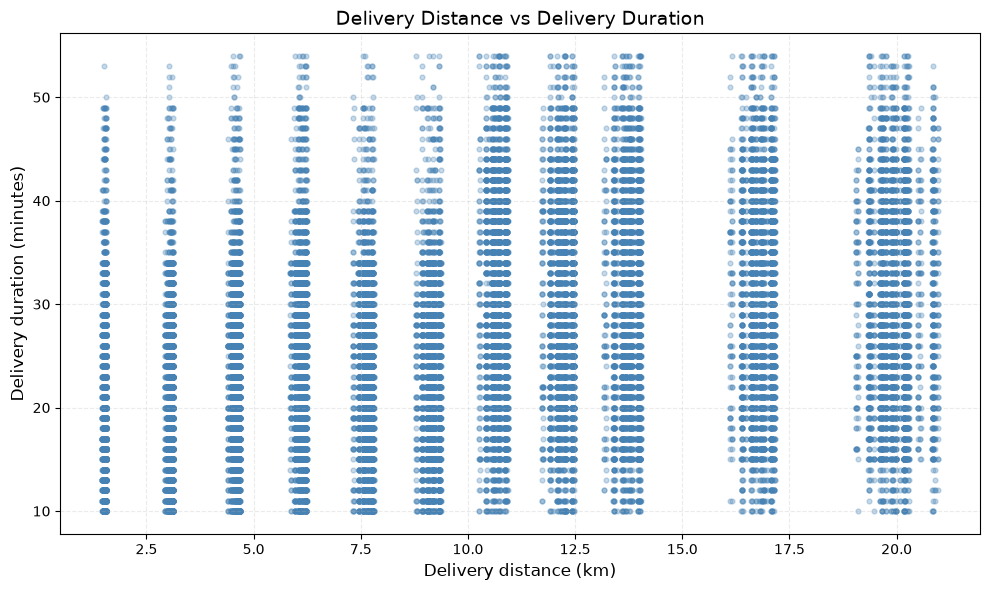

In [10]:
plt.figure(figsize=(10,6))

plt.scatter(
    x=df_B['Distance_km'],
    y=df_B['Time_taken (min)'],
    color='steelblue',
    s=12,
    alpha=0.3
)

plt.title('Delivery Distance vs Delivery Duration', fontsize=14)
plt.xlabel('Delivery distance (km)', fontsize=12)
plt.ylabel('Delivery duration (minutes)', fontsize=12)

plt.grid(alpha=0.25, linestyle='--')
plt.tight_layout()

plt.savefig(VISUALIZATIONS_PATH / '04_distance_vs_duration.png',
            dpi=300, bbox_inches='tight')
plt.show()

### Interpretation

The scatter plot shows a **positive association**: longer delivery distances generally tend to occur alongside longer delivery durations. The Pearson correlation is approximately **0.3205**, indicating a positive but not particularly strong linear relationship. Distance may be relevant to delivery duration, but the plot does not show that distance is the only factor involved.

**Limitation:** The distance values depend on Scenario B, including the unverified absolute-value treatment of negative restaurant coordinates. The points also overlap, so individual observations are difficult to distinguish. The correlation measures linear association, not causation.

## 6. Vehicle Comparison — Box Plot

A box plot allows us to compare the distribution of delivery durations across vehicle categories. It displays the median, the interquartile range (the box), whiskers and potential outliers.

We keep the vehicle order explicit so that the labels match the data shown in each box.

In [11]:
# Keep the same vehicle order for the data and the x-axis labels
vehicle_order = ['motorcycle', 'bicycle', 'scooter', 'electric_scooter']

vehicle_summary = df.groupby('Type_of_vehicle')['Time_taken (min)'].apply(list)
vehicle_summary = vehicle_summary.reindex(vehicle_order)

# Display group sizes and medians for reference
vehicle_stats = df.groupby('Type_of_vehicle')['Time_taken (min)'].agg(
    delivery_count='count',
    median_duration='median'
).reindex(vehicle_order)

vehicle_stats

,delivery_count,median_duration
Type_of_vehicle,,
motorcycle,26429,26.0
bicycle,68,26.0
scooter,15273,24.0
electric_scooter,3814,24.0


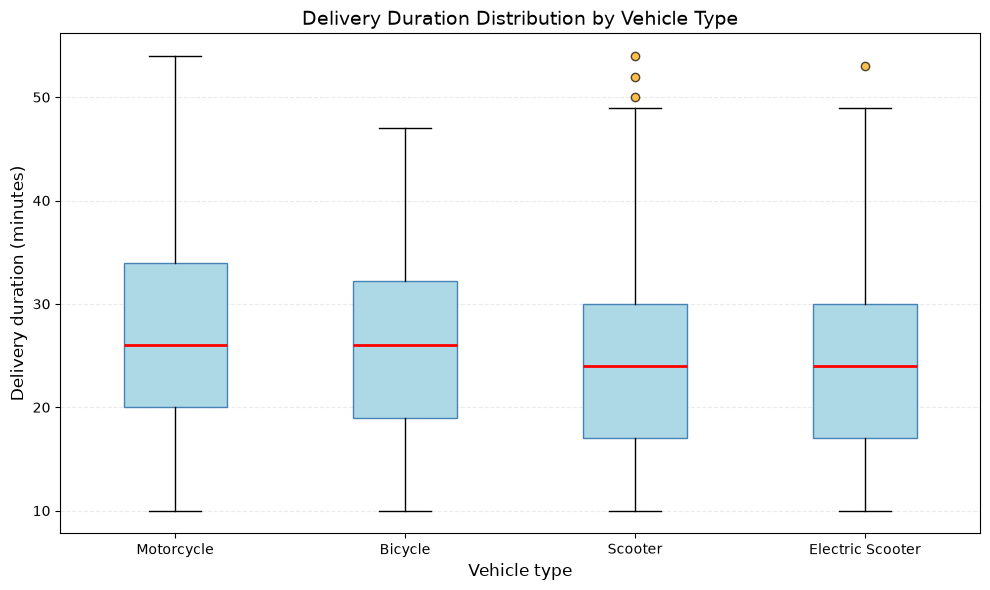

In [12]:
plt.figure(figsize=(10,6))

plt.boxplot(
    vehicle_summary.values,
    tick_labels=['Motorcycle', 'Bicycle', 'Scooter', 'Electric Scooter'],
    patch_artist=True,
    showfliers=True,
    boxprops=dict(facecolor='lightblue', edgecolor='steelblue'),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markerfacecolor='orange',
                    markersize=6, alpha=0.7)
)

plt.title('Delivery Duration Distribution by Vehicle Type', fontsize=14)
plt.xlabel('Vehicle type', fontsize=12)
plt.ylabel('Delivery duration (minutes)', fontsize=12)

plt.grid(axis='y', alpha=0.25, linestyle='--')
plt.tight_layout()

plt.savefig(VISUALIZATIONS_PATH / '05_vehicle_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

### Interpretation

Motorcycles and bicycles have a median delivery duration of approximately **26 minutes**, while scooters and electric scooters have a lower median of approximately **24 minutes**. The boxes show the middle 50% of observations (the interquartile range), and the plot also shows several upper outliers for scooters and an upper outlier for electric scooters. The bicycle group is very small (**68 deliveries**) compared with motorcycles (**26,429 deliveries**), so its distribution should be interpreted cautiously.

**Limitation:** The box plot compares vehicle groups without controlling for other factors such as traffic, weather or distance. The small bicycle sample also makes its comparison less reliable than comparisons involving the larger groups.

## 7. Export check

The five charts are saved as PNG files in the project's `visualizations/` folder. This final check confirms that the expected files exist and reports their file sizes.

In [13]:
chart_files = [
    '01_delivery_duration_distribution.png',
    '02_traffic_comparison.png',
    '03_weather_comparison.png',
    '04_distance_vs_duration.png',
    '05_vehicle_comparison.png'
]

for filename in chart_files:
    chart_path = VISUALIZATIONS_PATH / filename
    print(filename, "| exists:", chart_path.exists(),
          "| size:", f'{chart_path.stat().st_size:,} bytes' if chart_path.exists() else 'Not found')

01_delivery_duration_distribution.png | exists: True | size: 89,315 bytes
02_traffic_comparison.png | exists: True | size: 104,437 bytes
03_weather_comparison.png | exists: True | size: 124,826 bytes
04_distance_vs_duration.png | exists: True | size: 926,660 bytes
05_vehicle_comparison.png | exists: True | size: 96,103 bytes
